# Experiment 7: recruitment, containment, response similarity, breadth, and sparseness

Stages 1–4 of the overlap/selectivity workflow quantify recruitment, signed response-window activity, containment, response-pattern similarity, family response breadth, continuous response profiles, and within-family lifetime sparseness. Summary panels are displayed **left then right**, in the same functional order and with matching scales; the remaining grids retain mirrored left/right columns. Independent-trial preference validation remains for a later stage.

This notebook runs independently of notebook 01. It reuses its cohort, portable loading, timing, and overlap/count activity criteria. All analyses preserve kept-neuron identities and weight fish equally. Response similarity reuses the prepared stage-1 data without loading or reclassifying it.

The labels R300, R600, RF600, F300, F600, and DF300 denote **stimulus variants**. Interpret the plots descriptively, without assuming an anatomical hierarchy, a frequency-only manipulation, or biological equivalence.


## 1. Setup

Find the repository and import the shared loading, analysis, figure, and reporting owners.


In [47]:
from pathlib import Path
import sys
import importlib
from IPython.display import display
import matplotlib.pyplot as plt

repo_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'src').is_dir())
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import src.plotting_common as plot_common
import src.plotting_diagnostics as plotting_diagnostics
import src.stimulus_specificity as stimulus_specificity
import src.neuron_ordering as neuron_ordering
import src.plotting_specificity as plotting_specificity
import src.several_fish_loading as several_loading
import src.several_fish_diagnostics as several_diagnostics
import src.several_fish_figures as several_figures
import src.several_fish_reporting as several_reporting
# Reload changed dependencies before modules that import their functions.
for module in (plot_common, plotting_diagnostics, stimulus_specificity, neuron_ordering, plotting_specificity,
               several_loading, several_diagnostics, several_reporting, several_figures):
    importlib.reload(module)


## Publication layout and export

The notebook uses **6 pt Arial** at final print size. Sections **5, 7, 13, 14,
18, 19 and 20** each produce four independent **45 × 27.5 mm** figures. Individual
fish are gray dots; the equally weighted fish mean is a black line. Legends show
only “Fish” and “Mean.” Sections 18–19 also use dots for individual CDF values.

Width and height controls remain beside every plotting call for later resizing.
Each panel has its own title and axis labels. Left/right scales and the configured
stimulus order match the original analysis. Other figure layouts remain unchanged.

Set `EXPORT_PUBLICATION_FIGURES=True` and run the export cell after reviewing the
plots. It writes each panel independently as editable PDF/SVG and 600 dpi PNG.
Exported canvas dimensions match the configured millimetres without tight cropping.


In [48]:
# Physical sizes are millimetres; font sizes are points at the final print size.
MM = 1 / 25.4
PUBLICATION_STYLE = {
    'font.family': 'Arial', 'font.size': 6,
    'axes.labelsize': 6, 'axes.titlesize': 6, 'figure.titlesize': 6,
    'xtick.labelsize': 6, 'ytick.labelsize': 6, 'legend.fontsize': 6,
    'legend.title_fontsize': 6, 'axes.linewidth': 0.6,
    'lines.linewidth': 1.0, 'lines.markersize': 3,
    'xtick.major.width': 0.6, 'ytick.major.width': 0.6,
    'xtick.major.size': 2.5, 'ytick.major.size': 2.5,
    'figure.dpi': 150, 'savefig.dpi': 600, 'savefig.bbox': None,
    'pdf.fonttype': 42, 'ps.fonttype': 42, 'svg.fonttype': 'none',
    'mathtext.fontset': 'dejavusans', 'figure.facecolor': 'white',
}
plt.rcParams.update(PUBLICATION_STYLE)
EXPORT_PUBLICATION_FIGURES = False  # Enable after reviewing the figures.
PUBLICATION_FORMATS = ('pdf', 'svg', 'png')
PUBLICATION_DPI = 600
PUBLICATION_DIR = repo_root / 'notebooks/calcium/exp_07_trans_stat/publication_figures/02'


## 2. Cohort, mirrored stimulus groups, and activity criteria

Keep experiment-specific choices here. The activity criteria match notebook 01's overlap/count figures. `data_base=None` discovers OneDrive automatically; a manual override is the parent of the university OneDrive folder.


In [49]:
SIDE_GROUPS = {
    'left': {
        'control': 'LeBcontrol',
        'rocking': ['R300Le', 'R600Le', 'RF600Le'],
        'flicker': ['F300Le', 'F600Le', 'DF300Le'],
    },
    'right': {
        'control': 'RiBcontrol',
        'rocking': ['R300Ri', 'R600Ri', 'RF600Ri'],
        'flicker': ['F300Ri', 'F600Ri', 'DF300Ri'],
    },
}
CONDITION_LABELS = ['Control', 'R300', 'R600', 'RF600', 'F300', 'F600', 'DF300']
USER_SETTINGS = {
    'experiment_name': 'Exp_7_trans_stat',
    'analysis_label': 'Exp 7 recruitment and containment',
    'data_base': None,
    'fish_ids': ['L742_f03', 'L742_f05', 'L742_f06', 'L742_f09', 'L742_f10'],
    'selected_blocks': ['B1', 'B2', 'B3', 'B4'],
    'verbose_loading': False,
    'timing': {'fps_2p': 2.0, 't_pre_s': 5.0, 't_post_s': 25.0,
               'motion_onset_s': 8.0, 'tau_s': 6.0},
    'stim_order': [7, 8, 10, 12, 3, 5, 1, 14, 9, 11, 13, 4, 6, 2],
}
ACTIVE_SETTINGS = {
    'active_fraction_threshold': 0.10,
    'min_epoch_s': 1.0,
    'min_active_reps': 2,
    'expected_reps': 4,
    'require_expected_reps': True,
}
REPORT_SETTINGS = {
    'save_report': False,
    'run_label': 'exp7_recruitment_containment',
    'report_format': 'html',
    'export_notebook': True,
    'fallback_to_html': True,
    'comments': 'Stages 1–4; enable saving only after reviewing both sides.',
}


## 3. Independent loading and preflight

Load all five fish, validate the configured stimuli, and show the selected roots. The analysis step also validates the named groups and filtered-raster/continuous-trace row contract for every fish.


In [50]:
raster_inputs = several_loading.load_and_preflight_fish_raster_inputs(USER_SETTINGS)
globals().update(raster_inputs)
print('Data root:', main_path)
print('Analysis root:', analysis_path)
print(f'Loaded {len(fish_ids)} fish.')


Data root: C:\Users\suribear\OneDrive - Université de Lausanne\Lab\Data\2p
Analysis root: C:\Users\suribear\OneDrive - Université de Lausanne\Lab\Analysis
Loaded 5 fish.


## 4. Build aligned analysis inputs once

Recruitment uses the canonical significant-raster activity decision. Continuous activity uses signed z-score AUC across the **same kept neurons**, including inactive neurons, divided by the actual trapezoidal integration span. This is response-window z-score activity, with no additional baseline subtraction or clipping at zero.

The existing timing helper starts each window 8 s after stimulus onset and requests stimulus motion duration plus `2 * tau_s`. It clips to the available aligned trace. The table below makes requested and observed durations explicit; conclusions concern these observed windows. Raw AUC, sample bounds, individual-neuron responses, and fish identities remain in `analysis['tables']`.


In [51]:
analysis = several_diagnostics.build_recruitment_containment_analysis(
    all_fish_data, fish_ids, SIDE_GROUPS, timing, ACTIVE_SETTINGS, CONDITION_LABELS,
)
display(analysis['tables']['window_summary'])


,side,condition,requested_duration_s,observed_duration_s,integration_span_s,fish_with_clipped_window
0,left,Control,20.217,17.0,16.5,5
1,left,R300,19.917,17.0,16.5,5
2,left,R600,19.617,17.0,16.5,5
3,left,RF600,19.917,17.0,16.5,5
4,left,F300,20.217,17.0,16.5,5
5,left,F600,20.217,17.0,16.5,5
6,left,DF300,20.217,17.0,16.5,5
7,right,Control,20.217,17.0,16.5,5
8,right,R300,19.917,17.0,16.5,5
9,right,R600,19.617,17.0,16.5,5


## 5. Recruitment and response-window activity

Four separate figures show recruitment and response-window activity for left and right stimuli. Recruitment is the fraction of kept neurons active; activity is mean normalized AUC across that same population. Gray dots show fish values without identities or connecting lines; the black line and diamonds show their equally weighted mean. Both sides share the corresponding y scale. The activity panel combines recruitment and response magnitude; it does not establish stronger activity specifically within shared active neurons.


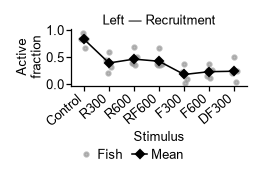

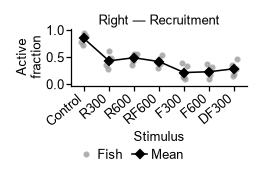

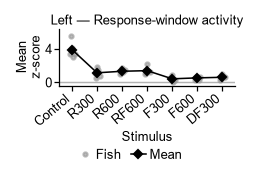

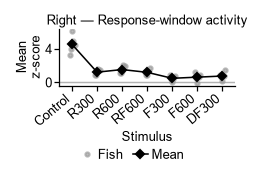

In [52]:
# Each figure is independent; edit these dimensions for this section.
PANEL_WIDTH_MM, PANEL_HEIGHT_MM = 45, 27.5
FIGSIZE = (PANEL_WIDTH_MM * MM, PANEL_HEIGHT_MM * MM)
recruitment_panels = several_figures.plot_recruitment_activity_summary(
    analysis, figsize=FIGSIZE,
    separate=True, individual_style='anonymous_points',
)
for figure, axis in recruitment_panels.values():
    display(figure)
    plt.close(figure)


## 6. Directional containment and Jaccard overlap

Top: row A / column B is `|A intersection B| / |A|`, the fraction of A-responsive neurons also active to B. Bottom: Jaccard is intersection divided by union. Matrices are means of per-fish fractions, without weighting fish by neuron count. All heatmaps use the same 0-1 color scale. Gray cells are undefined; empty populations are not reported as zero overlap. Individual fish matrices and valid-fish counts remain available in the result tables.


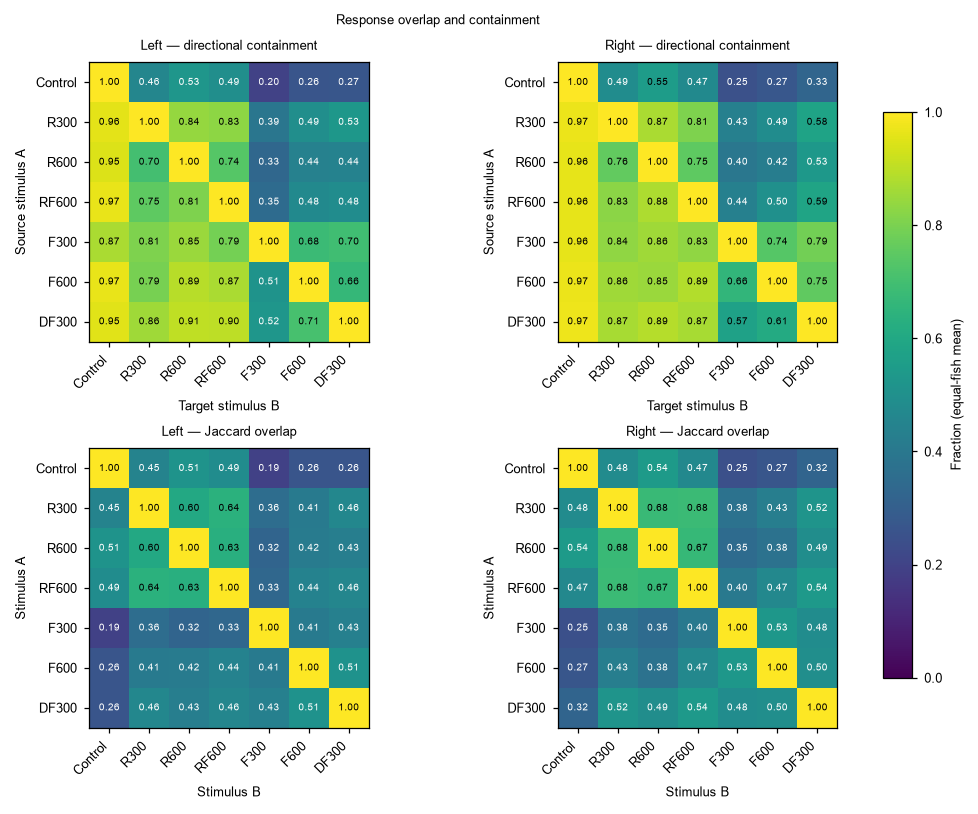

In [53]:
FIGSIZE = (180 * MM, 135 * MM)
HEATMAP_CMAP = 'viridis'
fig_overlap, axes_overlap = several_figures.plot_recruitment_containment_matrices(
    analysis, figsize=FIGSIZE, cmap=HEATMAP_CMAP,
)
plt.show()


## 7. Containment in control and in all rocking variants

The control-containment figures show the fraction of each weaker-stimulus population also responding to its side's control. The all-rocking-containment figures show the fraction of each flicker population responding to **every rocking variant**, using their intersection, not their union. The denominator is the source stimulus's active population. Empty sources leave gaps. Non-contained counts and fractions are retained in `analysis['tables']['containment_summary']`.


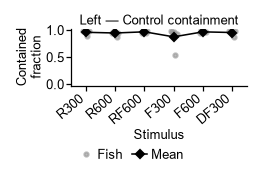

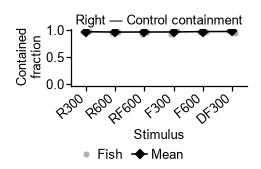

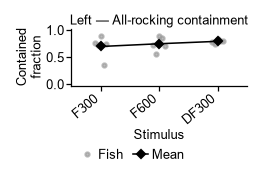

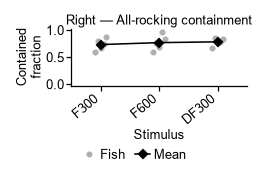

In [54]:
# Each figure is independent; edit these dimensions for this section.
PANEL_WIDTH_MM, PANEL_HEIGHT_MM = 45, 27.5
FIGSIZE = (PANEL_WIDTH_MM * MM, PANEL_HEIGHT_MM * MM)
containment_panels = several_figures.plot_recruitment_containment_summary(
    analysis, figsize=FIGSIZE,
    separate=True, individual_style='anonymous_points',
)
for figure, axis in containment_panels.values():
    display(figure)
    plt.close(figure)


## 8. Prepare response-pattern similarity in both neuron populations

Reuse the **signed duration-normalized AUC** already stored for each kept neuron and stimulus, with no extra clipping, normalization, or neuron classification. Calculate each metric separately within each fish and side before averaging the defined per-fish values with equal weight (arithmetic means, not Fisher-transformed correlations).

Compare two fixed populations: **all kept neurons**, and the **core responsive to every rocking variant** on that side. The core is selected separately for each fish and side using the existing activity decisions; the same selected neurons are used for every stimulus comparison. The table reports their sizes. Pairwise finite-response counts and valid-fish counts are retained in `similarity['tables']`. Constant vectors, zero norms, and empty cores retain undefined values where appropriate; gray cells are not zero similarity.

These metrics describe the observed responses. Trial-independent reliability and preference validation are not included yet.


In [55]:
similarity = several_diagnostics.build_response_similarity_comparison(analysis)
display(similarity['tables']['response_similarity_population_summary'])


,fish_id,side,all_kept,all_rocking
0,L742_f03,left,599,154
1,L742_f03,right,599,152
2,L742_f05,left,607,116
3,L742_f05,right,607,131
4,L742_f06,left,314,166
5,L742_f06,right,314,131
6,L742_f09,left,458,114
7,L742_f09,right,458,147
8,L742_f10,left,372,86
9,L742_f10,right,372,156


## 9. Jaccard: recruitment overlap across populations

Rows compare all kept neurons (top) with the all-rocking core (bottom); columns always mirror left/right. The all-kept results reuse the existing stage-1 Jaccard matrices. The core results apply the same Jaccard helper after selecting that population.

**Rocking-versus-rocking Jaccard equals one inside the shared-rocking core by construction.** It is a consequence of selecting neurons responsive to all rocking variants, not independent evidence of equivalent responses. Flicker overlap can still differ within this selected population. Every panel uses the same 0-1 scale.


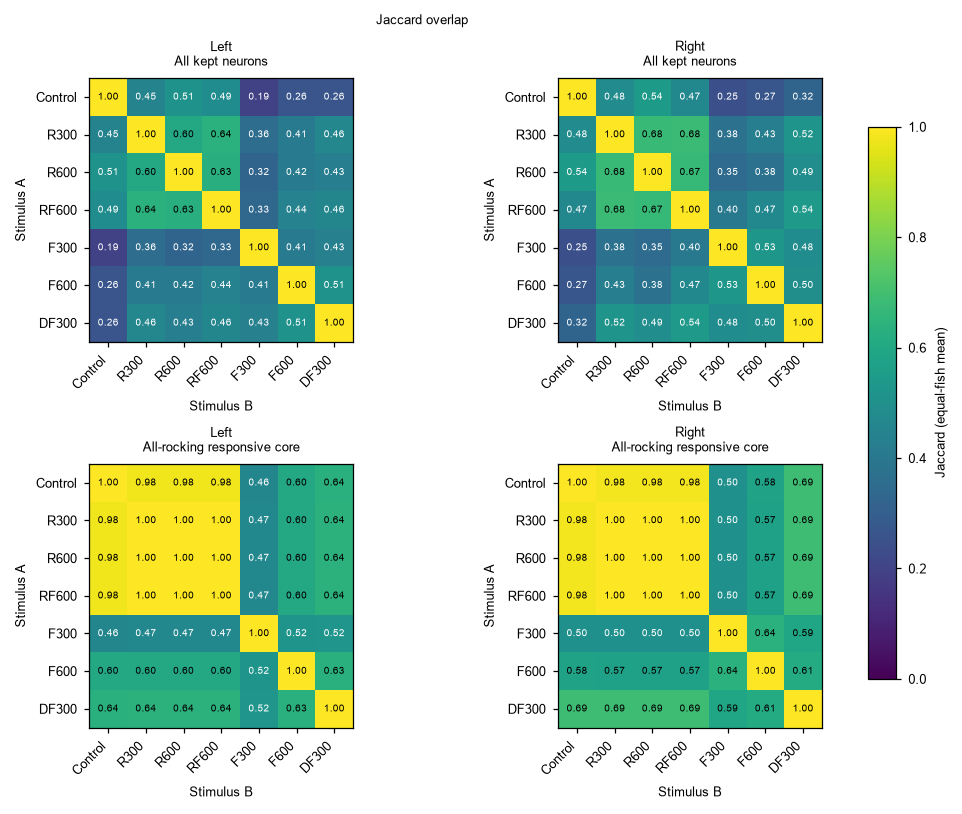

In [56]:
FIGSIZE = (180 * MM, 135 * MM)
HEATMAP_CMAP = 'viridis'
fig_similarity_jaccard, axes_similarity_jaccard = several_figures.plot_response_similarity_comparison(
    similarity, metric='jaccard', figsize=FIGSIZE, cmap=HEATMAP_CMAP,
)
plt.show()


## 10. Pearson: relative continuous-response patterns

Pearson compares how responses vary across neurons after centering each stimulus vector and removing its overall scale. This can reveal differences within populations that share binary activity decisions. All seven conditions, including control as a reference, retain the same order on both sides. The common -1 to 1 color scale is centered at zero; undefined correlations stay gray.

High Pearson similarity can coexist with different overall response magnitudes. The shared-rocking-core panels are conditional on the selected population; they are descriptive, not an independent validation of selectivity.


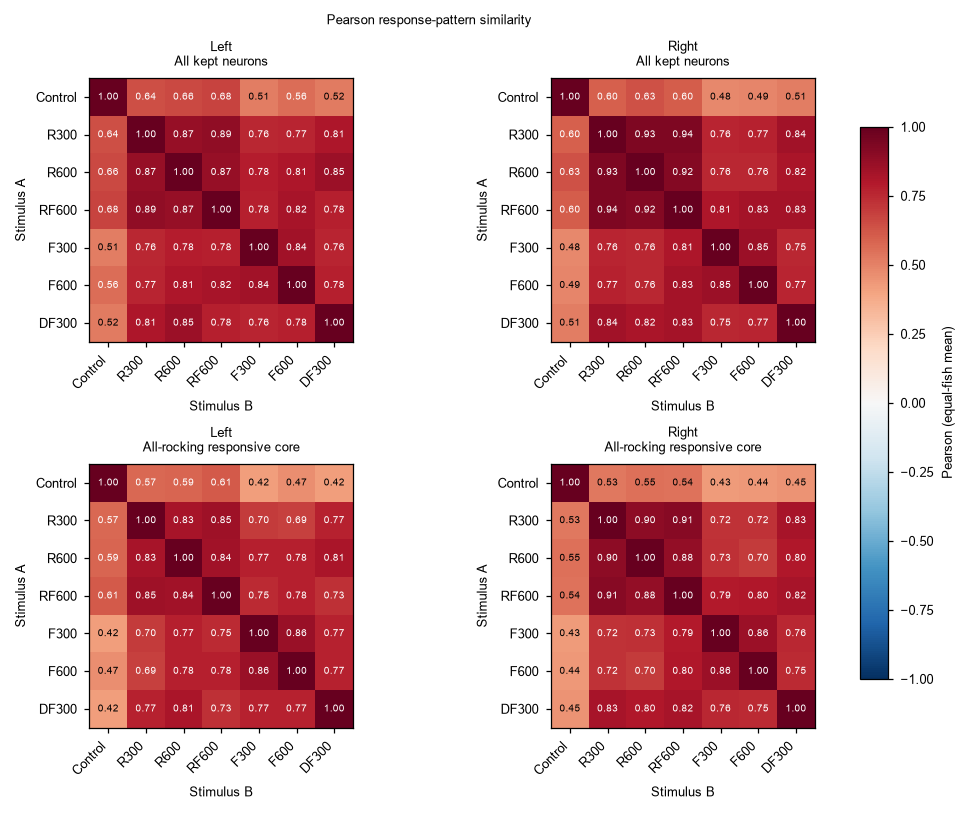

In [57]:
FIGSIZE = (180 * MM, 135 * MM)
HEATMAP_CMAP = 'RdBu_r'
fig_similarity_pearson, axes_similarity_pearson = several_figures.plot_response_similarity_comparison(
    similarity, metric='pearson', figsize=FIGSIZE, cmap=HEATMAP_CMAP,
)
plt.show()


## 11. Cosine: continuous-response vector direction

Cosine compares stimulus response vectors without centering them. Signed responses are preserved; positive rescaling leaves cosine unchanged, while offsets can affect it. It complements Pearson and recruitment overlap rather than establishing identical response strength or biological meaning. The common -1 to 1 color scale is centered at zero; zero-norm comparisons remain undefined.


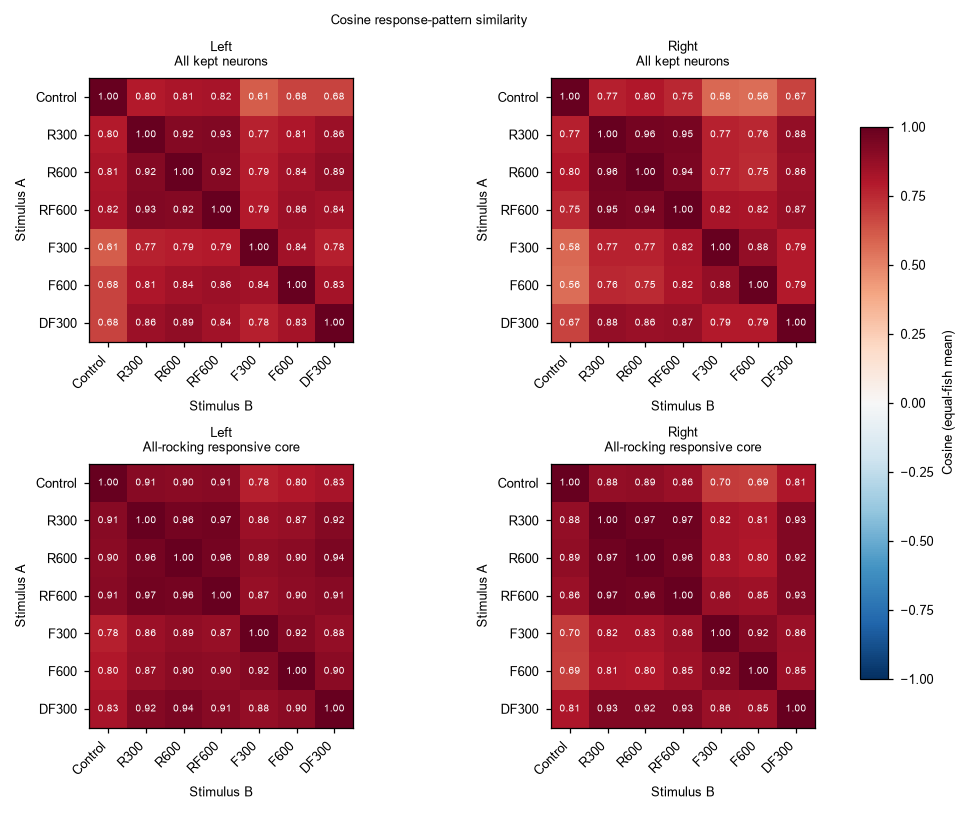

In [58]:
FIGSIZE = (180 * MM, 135 * MM)
HEATMAP_CMAP = 'RdBu_r'
fig_similarity_cosine, axes_similarity_cosine = several_figures.plot_response_similarity_comparison(
    similarity, metric='cosine', figsize=FIGSIZE, cmap=HEATMAP_CMAP,
)
plt.show()


## 12. Prepare response breadth and display profiles

Reuse the prepared activity decisions and signed normalized AUC, without reloading, reclassifying, or normalizing again. Within **rocking and flicker separately**, record each neuron's exact membership and number of active variants. Base tables retain all-kept denominators, including nonresponders. Additional family-responsive tables exclude zero-active categories and divide each count by the neurons active to at least one variant of that family, separately within each fish and side; sections 13–14 use these conditional fractions. Fish with no family-responsive neurons have undefined fractions and do not contribute to the mean. Summaries average per-fish fractions equally; complete counts, denominators, and valid-fish counts remain in `breadth_profiles['tables']`.


In [59]:
breadth_profiles = several_diagnostics.build_response_breadth_profiles(analysis, similarity)


## 13. Response breadth within each stimulus family

Four separate figures show rocking/flicker for left/right stimuli. Among neurons active to at least one variant of the plotted family, each belongs to exactly one category: active to 1, 2, or all 3 variants. Fractions sum to one within each fish/side/family with responders; zero-active neurons are excluded. Gray unconnected dots show individual fish values; the black line and diamonds show their equally weighted mean. These are threshold-based response memberships, not independently validated selectivity classes.


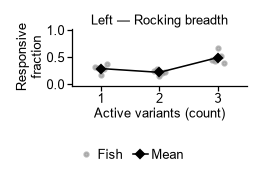

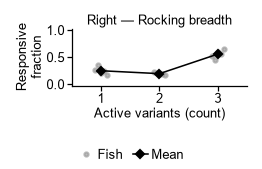

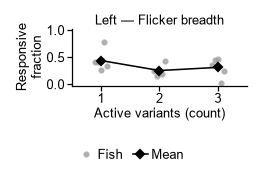

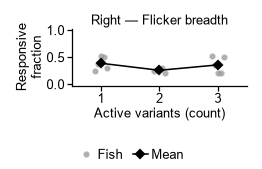

In [60]:
# Each figure is independent; edit these dimensions for this section.
PANEL_WIDTH_MM, PANEL_HEIGHT_MM = 45, 27.5
FIGSIZE = (PANEL_WIDTH_MM * MM, PANEL_HEIGHT_MM * MM)
breadth_panels = several_figures.plot_response_breadth_summary(
    breadth_profiles, mode='breadth', figsize=FIGSIZE,
    separate=True, individual_style='anonymous_points', denominator='family_responsive',
)
for figure, axis in breadth_panels.values():
    display(figure)
    plt.close(figure)


## 14. Exact stimulus-response combinations

The seven nonempty, mutually exclusive combinations separate family-responsive neurons responding to one particular variant, one particular pair, or all three. Every category is present even when its count is zero. Fractions use **neurons active to at least one variant of the plotted family**, separately within each fish and side, so a small exclusive category is not automatically evidence of specific tuning; threshold crossings and trial variability remain possible explanations.

For compact labels, each three-digit code follows the variant order printed on the x axis: `1` means active and `0` means inactive. For example, `101` means the first and third variants, and `000` is excluded because it represents no response to this family. Category order and values are unchanged. Gray dots show fish; the black line shows their equal-fish mean.


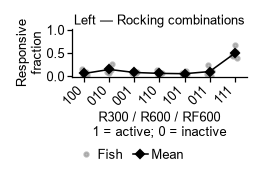

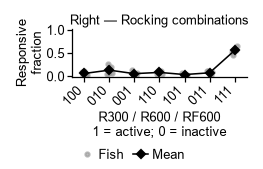

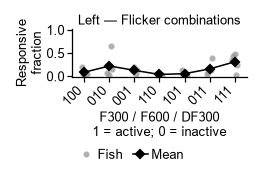

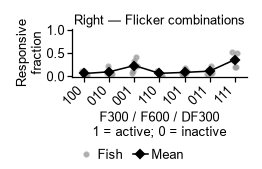

In [61]:
# Each figure is independent; edit these dimensions for this section.
PANEL_WIDTH_MM, PANEL_HEIGHT_MM = 45, 27.5
FIGSIZE = (PANEL_WIDTH_MM * MM, PANEL_HEIGHT_MM * MM)
combination_panels = several_figures.plot_response_breadth_summary(
    breadth_profiles, mode='combinations', figsize=FIGSIZE,
    separate=True, individual_style='anonymous_points', denominator='family_responsive',
)
for figure, axis in combination_panels.values():
    display(figure)
    plt.close(figure)


## 15. Continuous response profiles: all kept neurons

Each fish has its own row of mirrored left/right panels. Colors show the existing **signed duration-normalized AUC**, with no rectification or per-neuron scaling. Both population figures share one symmetric color scale spanning all finite values, including control; gray means missing. Fish are displayed separately, rather than pooled into a neuron-weighted summary.

Within each panel, neurons are grouped by their largest signed response among the **six weaker variants** in configured order, then descending largest response, with stable source-order ties. Rows lacking finite weaker-variant values appear last. This is a descriptive display order, not validated preference. Rows across sides need not correspond; displayed identities and values are retained in `response_profile_rows`.


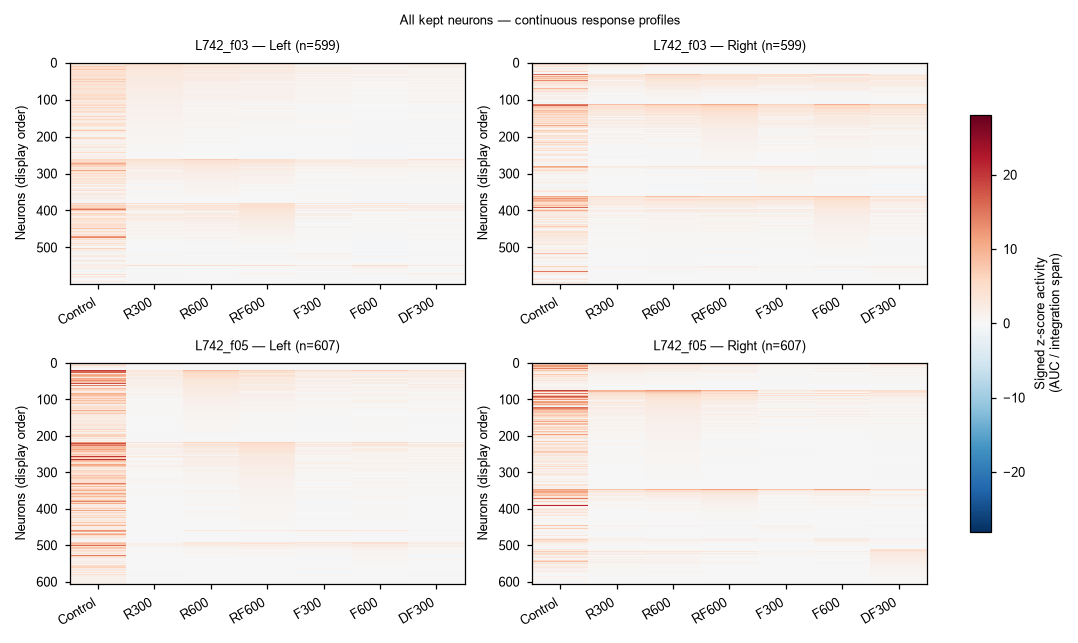

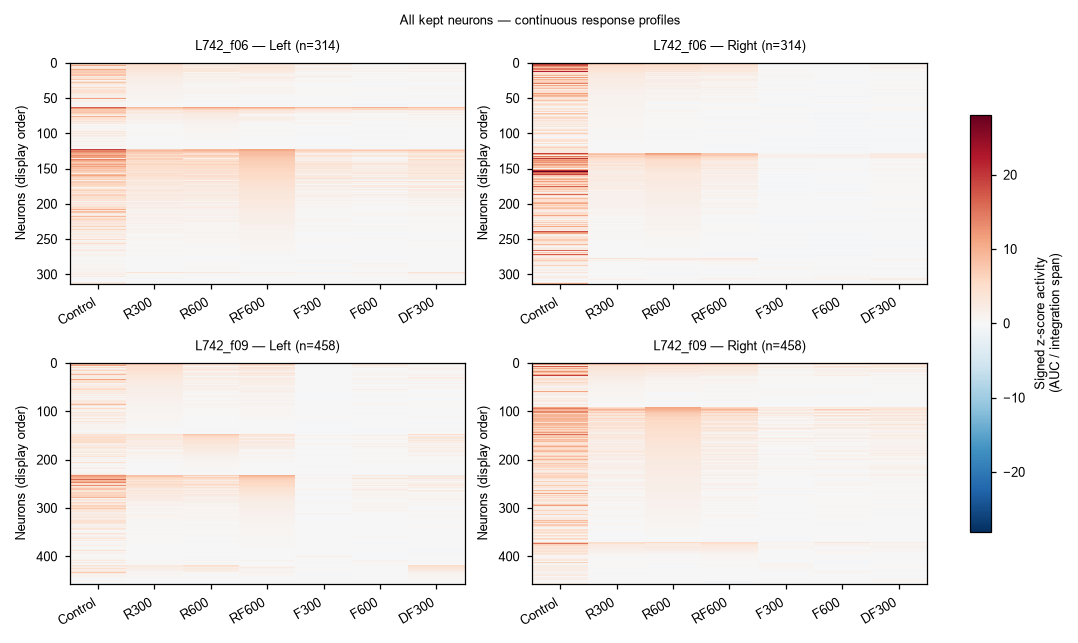

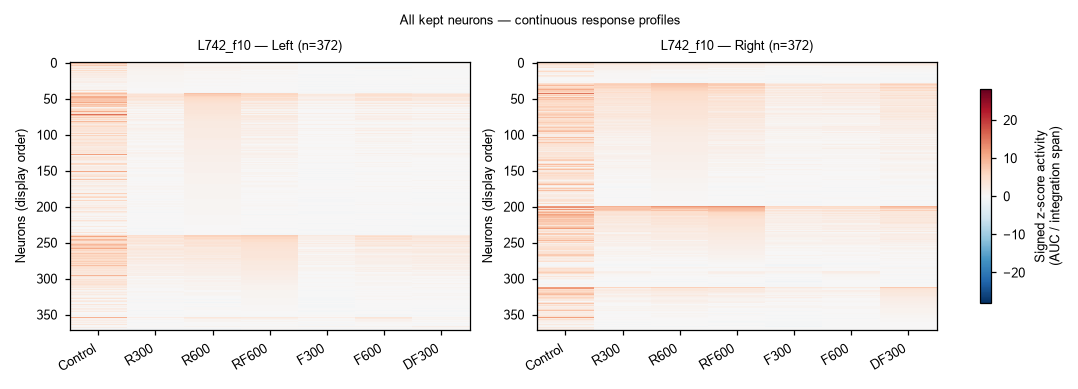

In [62]:
# At most two fish per block: keep room for other publication panels.
PROFILE_FISH_PER_FIGURE = 2
PROFILE_WIDTH_MM = 180
PROFILE_ROW_HEIGHT_MM = 43
PROFILE_CMAP = 'RdBu_r'
profile_figures_all_kept = {}
for start in range(0, len(fish_ids), PROFILE_FISH_PER_FIGURE):
    panel_fish = fish_ids[start:start + PROFILE_FISH_PER_FIGURE]
    FIGSIZE = (PROFILE_WIDTH_MM * MM, (20 + PROFILE_ROW_HEIGHT_MM * len(panel_fish)) * MM)
    figure, axes = several_figures.plot_response_profile_panels(
        breadth_profiles, population='all_kept', figsize=FIGSIZE,
        cmap=PROFILE_CMAP, fish_ids=panel_fish,
    )
    profile_figures_all_kept[f'profiles_all_kept_{start // PROFILE_FISH_PER_FIGURE + 1:02d}'] = figure
    plt.show()


## 16. Continuous response profiles: all-rocking responsive core

Use the same neurons already selected as responsive to every rocking variant on each side, with all seven condition columns and the **same color limits** as the all-kept figure. Although rocking membership is fixed by selection, continuous response strengths may differ. Left/right cores are selected independently, and neither membership nor display ordering establishes reproducible stimulus preference.


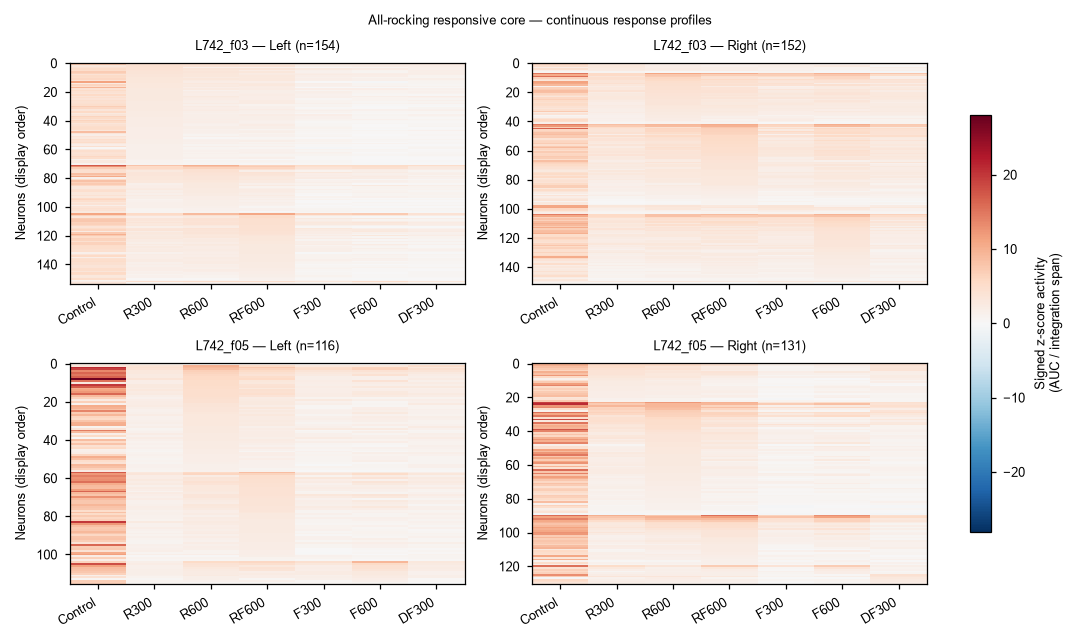

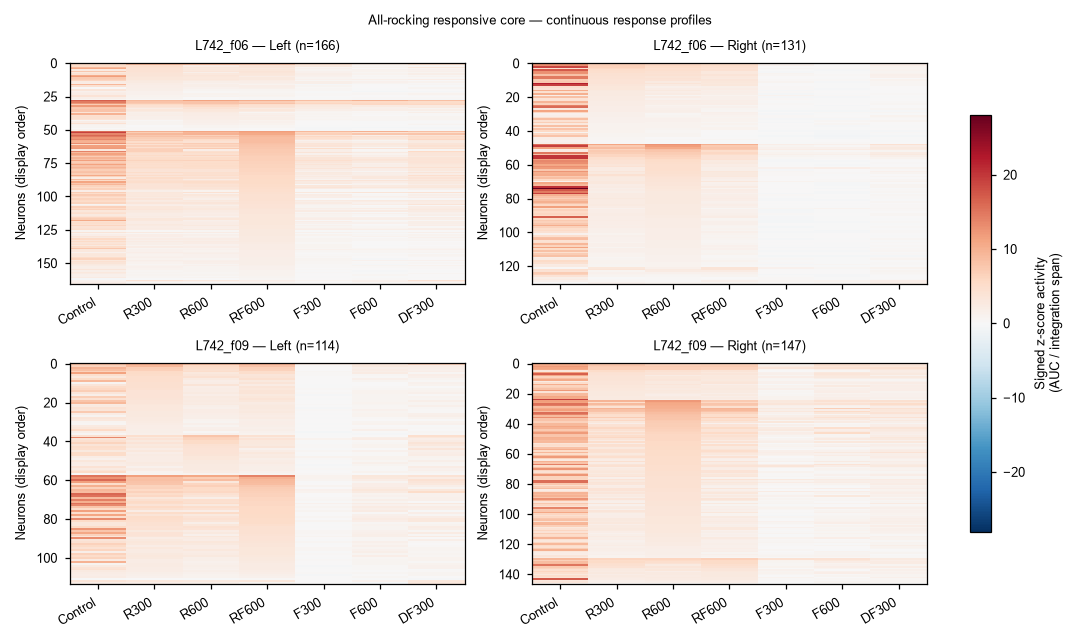

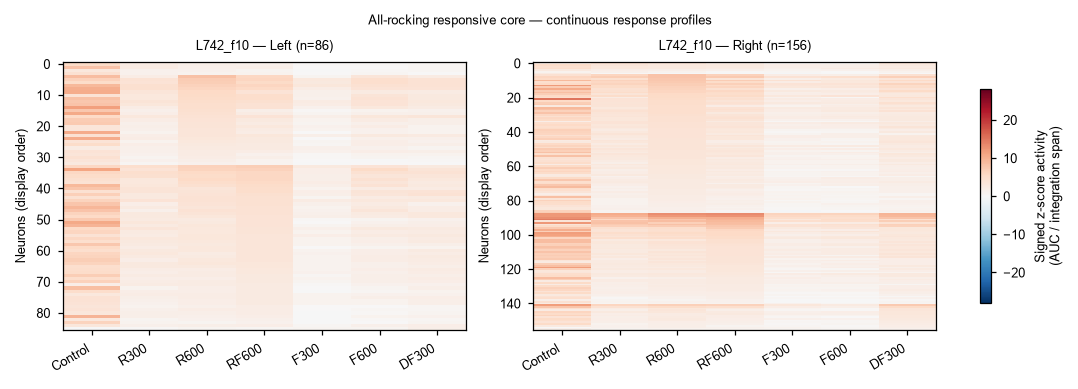

In [63]:
# At most two fish per block: keep room for other publication panels.
PROFILE_FISH_PER_FIGURE = 2
PROFILE_WIDTH_MM = 180
PROFILE_ROW_HEIGHT_MM = 43
PROFILE_CMAP = 'RdBu_r'
profile_figures_all_rocking = {}
for start in range(0, len(fish_ids), PROFILE_FISH_PER_FIGURE):
    panel_fish = fish_ids[start:start + PROFILE_FISH_PER_FIGURE]
    FIGSIZE = (PROFILE_WIDTH_MM * MM, (20 + PROFILE_ROW_HEIGHT_MM * len(panel_fish)) * MM)
    figure, axes = several_figures.plot_response_profile_panels(
        breadth_profiles, population='all_rocking', figsize=FIGSIZE,
        cmap=PROFILE_CMAP, fish_ids=panel_fish,
    )
    profile_figures_all_rocking[f'profiles_all_rocking_{start // PROFILE_FISH_PER_FIGURE + 1:02d}'] = figure
    plt.show()


## 17. Within-family lifetime sparseness

Calculate each neuron's response concentration across the **three rocking variants** and, separately, the **three flicker variants**, excluding control. This is sparseness across tested stimuli, not across time. Reuse the prepared signed duration-normalized AUC and the existing canonical metric:

\[
S = \frac{1 - (\operatorname{mean}(r_i))^2 / \operatorname{mean}(r_i^2)}{1-1/3},
\qquad r_i = \max(\text{signed normalized AUC}_i, 0).
\]

**0** means equal positive responses across the variants; **1** means a positive response confined to one. Negative values are clipped only for this metric; original signed responses remain in the tables and earlier figures. Incomplete three-variant profiles are excluded rather than treating missing values as zero. Complete profiles with no positive response have undefined sparseness, not zero. Numerical roundoff is bounded to [0, 1].

Keep the existing **all-kept** and side-specific **all-rocking core** populations without another activity filter. Counts below report defined, incomplete, nonpositive, and active-family neurons; per-neuron activity flags and signed/positive values remain in `family_sparseness['tables']`. Very small or subthreshold positive responses can yield high sparseness, so interpret it alongside response strength and breadth. It does not establish reproducible preference, inhibition selectivity, or specificity beyond these three tested variants.


In [64]:
SPARSENESS_CDF_GRID = [i / 100 for i in range(101)]
family_sparseness = several_diagnostics.build_family_lifetime_sparseness(
    breadth_profiles, cdf_grid=SPARSENESS_CDF_GRID,
)
display(family_sparseness['tables']['family_sparseness_summary'])


,population,side,family,mean_sparseness,valid_fish,n_population_neurons,n_defined_neurons,n_incomplete_neurons,n_no_positive_neurons,n_active_family_neurons,n_defined_active_neurons,n_neurons_with_negative_values
0,all_kept,left,rocking,0.329090,5,2350,2238,0,112,1298,1291,641
1,all_kept,left,flicker,0.515223,5,2350,2082,0,268,731,723,1221
2,all_rocking,left,rocking,0.085368,5,636,636,0,0,636,636,3
3,all_rocking,left,flicker,0.267525,5,636,629,0,7,492,490,96
4,all_kept,right,rocking,0.323438,5,2350,2242,0,108,1304,1295,664
5,all_kept,right,flicker,0.507713,5,2350,2133,0,217,849,835,1076
6,all_rocking,right,rocking,0.080344,5,717,717,0,0,717,717,7
7,all_rocking,right,flicker,0.293707,5,717,699,0,18,560,554,119


## 18. Lifetime sparseness distributions: all kept neurons

Four separate figures show rocking/flicker for left/right stimuli, on common 0–1 scales. Gray dots show each fish’s CDF evaluation values among its defined neurons; the black curve averages those fish distributions with equal weight at the configured evaluation points. The y value is the fraction with sparseness at or below x: a curve farther to the right indicates more concentrated positive responses. Contributing-fish and excluded-neuron counts are retained above and in the per-fish tables. Undefined neurons do not enter these conditional distributions.


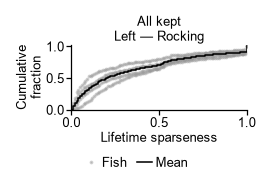

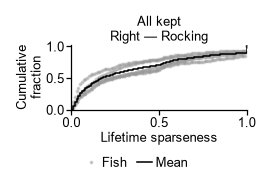

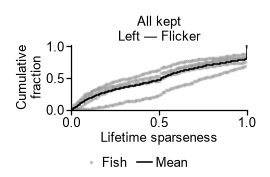

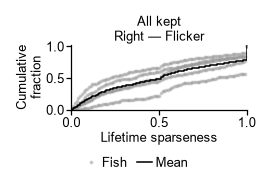

In [65]:
# Each figure is independent; edit these dimensions for this section.
PANEL_WIDTH_MM, PANEL_HEIGHT_MM = 45, 27.5
FIGSIZE = (PANEL_WIDTH_MM * MM, PANEL_HEIGHT_MM * MM)
sparseness_all_kept_panels = several_figures.plot_family_lifetime_sparseness(
    family_sparseness, population='all_kept', figsize=FIGSIZE,
    separate=True, individual_style='anonymous_points',
)
for figure, axis in sparseness_all_kept_panels.values():
    display(figure)
    plt.close(figure)


## 19. Lifetime sparseness distributions: all-rocking responsive core

Use the same side-specific all-rocking cores as before, with identical axes, anonymous gray CDF dots and a black mean curve. A neuron active to all rocking variants may still have unequal positive response strengths. Flicker sparseness is conditional on this rocking-selected population; it is not restricted to flicker-active neurons. Selection and metric calculation use the observed repetitions, so these curves remain descriptive.


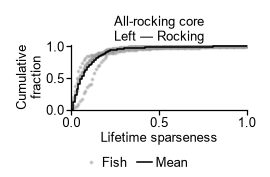

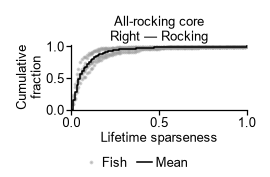

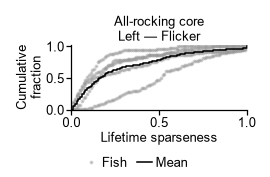

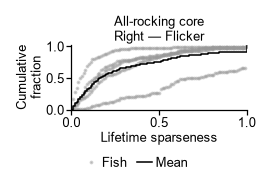

In [66]:
# Each figure is independent; edit these dimensions for this section.
PANEL_WIDTH_MM, PANEL_HEIGHT_MM = 45, 27.5
FIGSIZE = (PANEL_WIDTH_MM * MM, PANEL_HEIGHT_MM * MM)
sparseness_all_rocking_panels = several_figures.plot_family_lifetime_sparseness(
    family_sparseness, population='all_rocking', figsize=FIGSIZE,
    separate=True, individual_style='anonymous_points',
)
for figure, axis in sparseness_all_rocking_panels.values():
    display(figure)
    plt.close(figure)


## 20. Fish-level lifetime sparseness summary

For each fish, average sparseness across its defined neurons within each family and population. Gray unconnected dots show rocking/flicker means for each fish; the black line and diamonds average those fish means equally. Four separate figures compare all kept neurons and the all-rocking core for left/right stimuli. Fish without defined neurons remain missing. These are descriptive summaries, without a significance test or independent-trial preference validation.


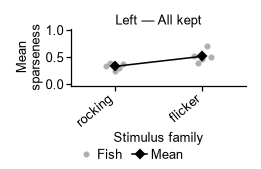

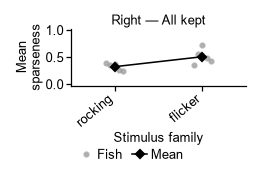

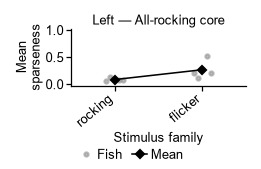

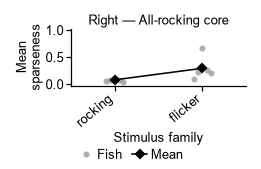

In [67]:
# Each figure is independent; edit these dimensions for this section.
PANEL_WIDTH_MM, PANEL_HEIGHT_MM = 45, 27.5
FIGSIZE = (PANEL_WIDTH_MM * MM, PANEL_HEIGHT_MM * MM)
sparseness_summary_panels = several_figures.plot_family_sparseness_summary(
    family_sparseness, figsize=FIGSIZE,
    separate=True, individual_style='anonymous_points',
)
for figure, axis in sparseness_summary_panels.values():
    display(figure)
    plt.close(figure)


## 21. Review before polishing individual figures

Compare recruitment and containment with response-pattern similarity, family breadth, exact combinations, continuous profiles, and within-family lifetime sparseness. Check whether apparent differences recur across fish and sides. Keep threshold-based membership distinct from response strength and positive-response concentration, and all-kept results distinct from the selected all-rocking core.

High similarity does not establish equivalence. Exclusive memberships, visually sorted profiles, and high sparseness do not establish reliable stimulus specificity. Review sparseness with its response strength, active flags, and defined-neuron counts. Independent-trial preference validation remains deferred. The descriptive analysis is ready for figure-by-figure review and polishing.


## 22. Optional reviewed-run report

Saving is disabled by default. Save the notebook with current outputs before enabling the existing report exporter.


In [68]:
notebook_path = repo_root / 'notebooks' / 'calcium' / 'exp_07_trans_stat' / '02_response_overlap_and_selectivity.ipynb'
report_result = several_reporting.save_analysis_report_run(
    settings=settings, report_settings=REPORT_SETTINGS, analysis_path=analysis_path,
    tables={**analysis['tables'], **similarity['tables'], **breadth_profiles['tables'],
            **family_sparseness['tables']}, notebook_path=notebook_path,
    report_name='02_response_overlap_and_selectivity_report',
    extra_metadata={
        'side_groups': SIDE_GROUPS, 'condition_labels': CONDITION_LABELS,
        'active_settings': ACTIVE_SETTINGS, 'data_root': main_path,
        'analysis_root': analysis_path, 'aggregation': 'equal_fish_weight',
        'response_similarity_populations': similarity['populations'],
        'response_similarity_values': 'signed_normalized_auc',
        'breadth_denominator': 'family_responsive_neurons_per_fish_side',
        'breadth_base_tables_denominator': 'all_kept_neurons',
        'profile_color_limit': breadth_profiles['profile_color_limit'],
        'profile_sort': 'largest_signed_weaker_variant_then_magnitude_stable',
        'family_sparseness_values': 'positive_part_of_signed_normalized_auc',
        'family_sparseness_missing': 'require_complete_family_profile',
        'family_sparseness_cdf_grid': SPARSENESS_CDF_GRID,
    },
)


Report saving is off. Set REPORT_SETTINGS['save_report'] = True to save this run.


## Export reviewed publication figures

Run after the plotting cells; the style cell controls whether files are written.


In [69]:
publication_figures = {
    **{f'05_{name}': figure for name, (figure, axis) in recruitment_panels.items()},
    **{f'07_{name}': figure for name, (figure, axis) in containment_panels.items()},
    **{f'13_{name}': figure for name, (figure, axis) in breadth_panels.items()},
    **{f'14_{name}': figure for name, (figure, axis) in combination_panels.items()},
    **{f'18_{name}': figure for name, (figure, axis) in sparseness_all_kept_panels.items()},
    **{f'19_{name}': figure for name, (figure, axis) in sparseness_all_rocking_panels.items()},
    **{f'20_{name}': figure for name, (figure, axis) in sparseness_summary_panels.items()},
    'containment_matrices': fig_overlap, 'similarity_jaccard': fig_similarity_jaccard,
    'similarity_pearson': fig_similarity_pearson, 'similarity_cosine': fig_similarity_cosine,
    **profile_figures_all_kept, **profile_figures_all_rocking,
}
if EXPORT_PUBLICATION_FIGURES:
    for name, figure in publication_figures.items():
        if figure is not None:
            plot_common.save_publication_figure(
                figure, PUBLICATION_DIR / name,
                formats=PUBLICATION_FORMATS, dpi=PUBLICATION_DPI,
            )
    print('Publication figures:', PUBLICATION_DIR)
